# Predicting Airbnb Listing Price Across Different Cities
**UE24CS352A Machine Learning, mini project 71**
Dhanush S S (PES1UG24AM082) and Harsha K R (PES1UG24AM114)

This notebook walks through the project end to end: the data, exploratory analysis, the
feature pipeline, one model trained live, and the results of all experiments
(produced by `scripts/train.py`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from airbnb import config as C
from airbnb.data import load_processed
pd.set_option("display.precision", 3)

## 1. Data
Inside Airbnb listings for New York City, Paris and Berlin (June/July 2026). `scripts/prepare_data.py` cleans them: price parsed and converted to USD, listings outside 10 to 1000 USD per night dropped, bathrooms parsed from text, amenities and text cleaned, distance to the city centre computed.

In [2]:
df = load_processed()
print(df.shape)
df.groupby("city")["price"].describe()

(75222, 45)


,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
berlin,8332.0,177.581,136.156,10.005,85.100,150.65,237.765,990.15
nyc,20890.0,222.761,177.167,10.230,94.192,169.80,285.500,1000.00
paris,46000.0,279.687,187.971,10.017,147.200,226.55,356.960,999.35


In [3]:
df[["city", "room_type", "property_type", "accommodates", "bedrooms", "bathrooms",
    "review_scores_rating", "dist_centre_km", "price"]].head()

,city,room_type,property_type,accommodates,bedrooms,bathrooms,review_scores_rating,dist_centre_km,price
0,nyc,Private room,Private room in condo,2,1.0,1.0,4.80,12.511,113.97
1,nyc,Entire home/apt,Entire rental unit,3,2.0,1.0,4.60,6.047,117.27
2,nyc,Private room,Private room in condo,1,NaN,1.0,5.00,6.001,80.06
3,nyc,Private room,Private room in rental unit,1,NaN,1.0,4.88,4.600,77.17
4,nyc,Private room,Private room in guest suite,2,NaN,1.0,4.89,7.410,202.47


## 2. Exploratory analysis
Prices are right-skewed, so every model predicts **log(price)**.

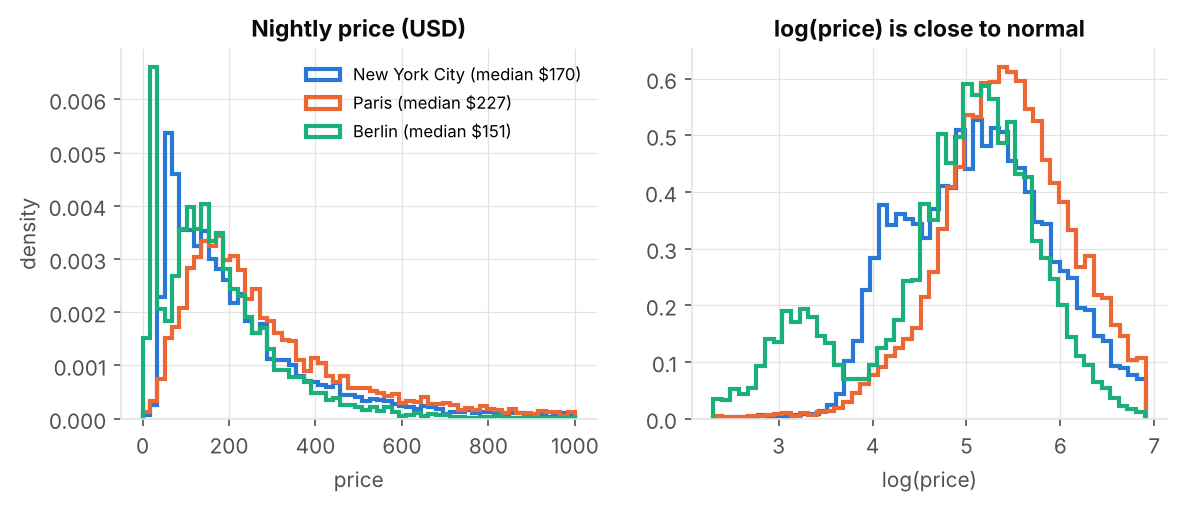

In [4]:
display(Image(str(C.FIG_DIR / "price_distribution.png")))

In [5]:
pd.crosstab(df.city, df.room_type, normalize="index").round(3)

room_type,Entire home/apt,Hotel room,Private room,Shared room
city,,,,
berlin,0.729,0.010,0.251,0.010
nyc,0.533,0.020,0.438,0.009
paris,0.890,0.006,0.102,0.002


In [6]:
num = ["accommodates", "bedrooms", "bathrooms", "beds", "minimum_nights", "dist_centre_km",
       "review_scores_rating", "number_of_reviews", "n_amenities", "availability_365", "has_license"]
corr = pd.DataFrame({c: df[df.city == c][num + ["log_price"]].corr()["log_price"].drop("log_price")
                     for c in C.CITIES})
corr.sort_values("nyc", ascending=False)

,nyc,paris,berlin
accommodates,0.477,0.551,0.460
has_license,0.391,0.141,0.729
beds,0.366,0.477,0.441
bedrooms,0.247,0.406,0.336
n_amenities,0.233,0.247,0.359
bathrooms,0.128,0.311,0.174
review_scores_rating,0.058,0.090,0.054
availability_365,0.057,0.072,-0.124
number_of_reviews,0.048,0.037,0.159
dist_centre_km,-0.349,-0.144,-0.115


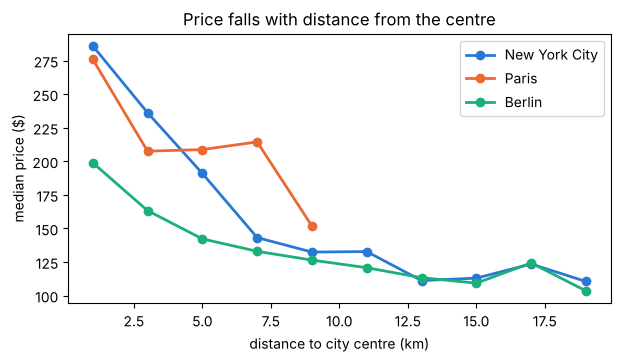

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for city, color in [("nyc", "#2a78d6"), ("paris", "#eb6834"), ("berlin", "#1baf7a")]:
    d = df[df.city == city].groupby(pd.cut(df.dist_centre_km, np.arange(0, 21, 2)), observed=True)["price"].median()
    ax.plot(np.arange(1, 20, 2)[:len(d)], d.values, marker="o", lw=2, color=color, label=C.CITIES[city]["name"])
ax.set(xlabel="distance to city centre (km)", ylabel="median price ($)", title="Price falls with distance from the centre")
ax.legend(); plt.show()

## 3. Feature pipeline and one model trained live
`build_preprocessor` (src/airbnb/features.py) combines four groups: continuous features (imputed + standardised), categorical one-hot, amenity multi-hot (top 60) and text (TF-IDF of title + description, uni+bi-grams, reduced to 50 dims with truncated SVD). Here we train XGBoost on Berlin (the smallest city) to show the full pipeline.

In [8]:
from airbnb.models import make_pipeline
from airbnb.evaluate import split_city, regression_metrics
train, test = split_city(df, "berlin")
pipe = make_pipeline("XGBoost")
pipe.fit(train, train.log_price)
print("features:", len(pipe.named_steps["features"].get_feature_names_out()))
regression_metrics(test.log_price, pipe.predict(test))

features: 189


{'R2_log': 0.8948056515158158,
 'MSE_log': 0.08608465143386136,
 'R2_usd': 0.7116143741710519,
 'MAE_usd': 38.897095169694396,
 'MedAPE_%': 15.777455205502694}

## 4. Results of all experiments (`python scripts/train.py`)
### E1: model comparison inside each city

In [9]:
e1 = pd.read_csv(C.RESULTS_DIR / "e1_model_comparison.csv")
e1.pivot(index="model", columns="train_city", values="R2_log")[["nyc", "paris", "berlin"]]

train_city,nyc,paris,berlin
model,,,
KNN,0.760,0.651,0.807
Neural net (MLP),0.797,0.798,0.851
Random Forest,0.825,0.799,0.874
Ridge (linear),0.769,0.707,0.865
XGBoost,0.850,0.838,0.895


In [10]:
e1.pivot(index="model", columns="train_city", values="MAE_usd")[["nyc", "paris", "berlin"]].round(1)

train_city,nyc,paris,berlin
model,,,
KNN,63.6,79.0,50.7
Neural net (MLP),59.9,64.5,48.1
Random Forest,55.2,64.1,43.2
Ridge (linear),64.3,74.1,45.0
XGBoost,50.4,56.8,38.9


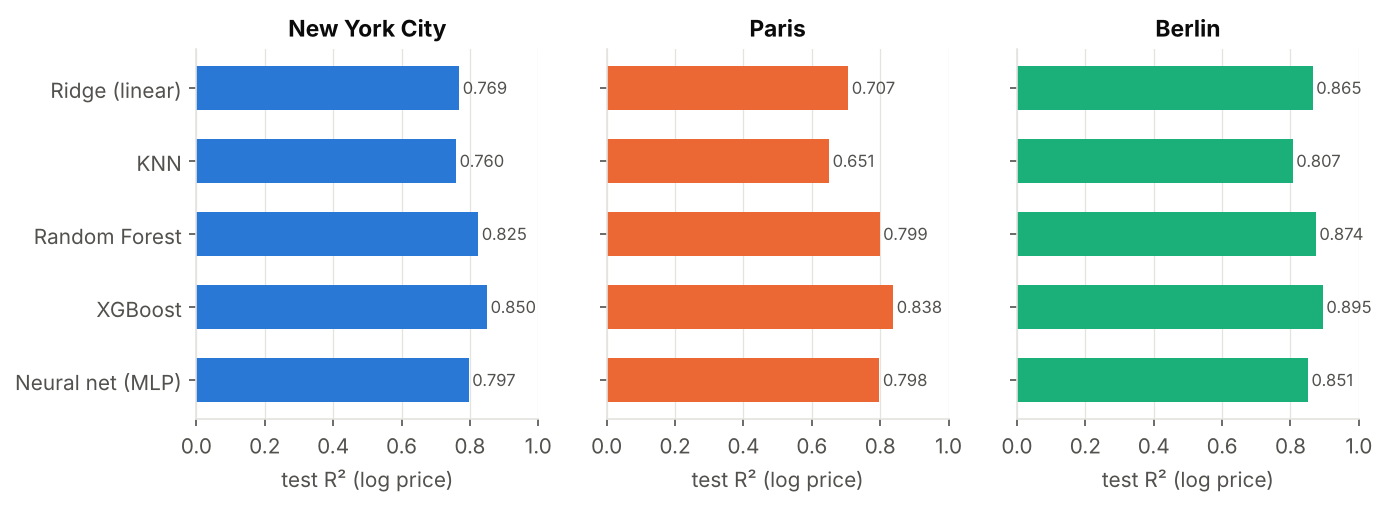

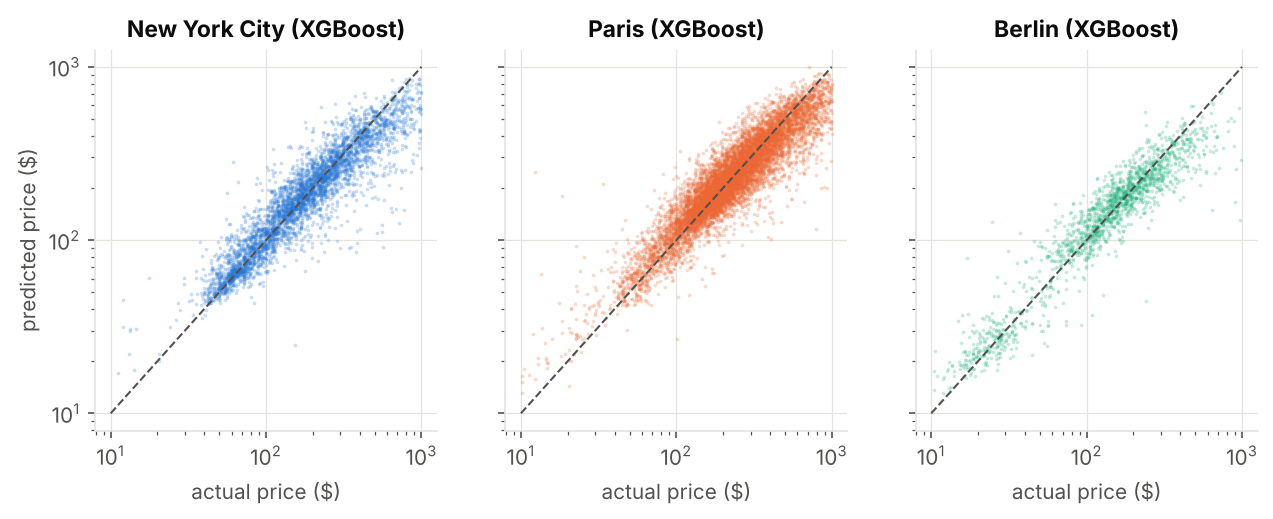

In [11]:
display(Image(str(C.FIG_DIR / "model_comparison.png")))
display(Image(str(C.FIG_DIR / "pred_vs_actual.png")))

### E2: which feature groups matter (XGBoost)

train_city,nyc,paris
features,,
C,0.843,0.817
C+O,0.856,0.833
C+O+T,0.850,0.838
O,0.556,0.379
T,0.532,0.375


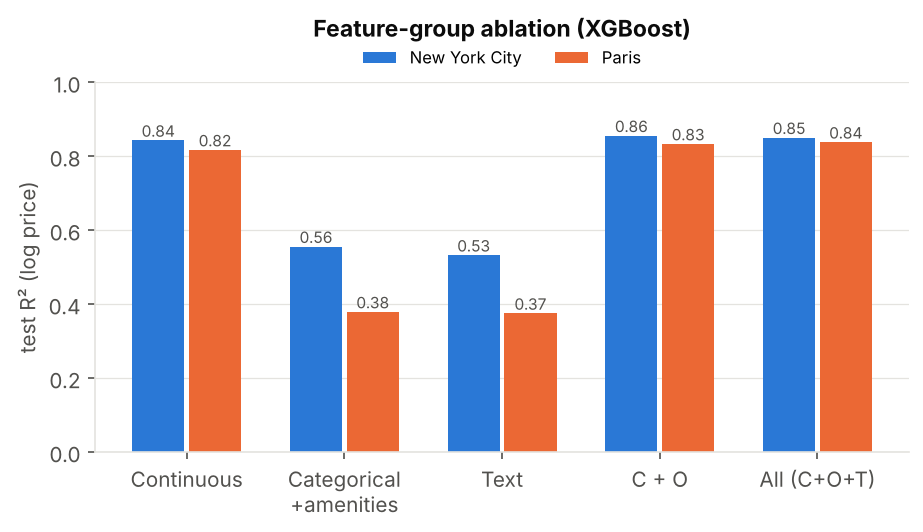

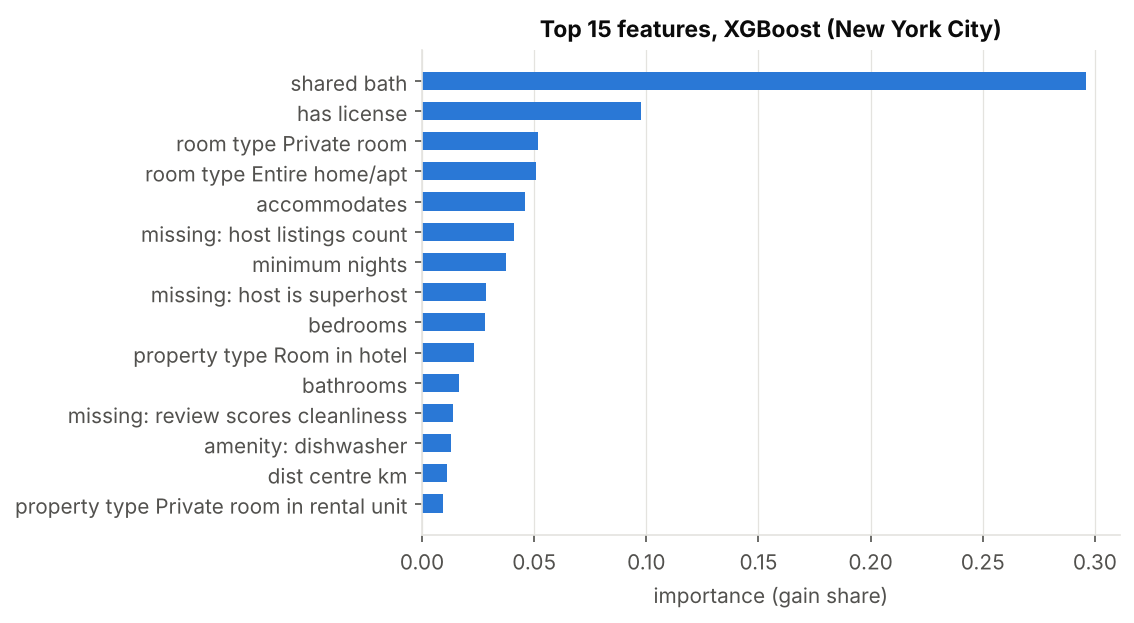

In [12]:
e2 = pd.read_csv(C.RESULTS_DIR / "e2_feature_ablation.csv")
display(e2.pivot(index="features", columns="train_city", values="R2_log"))
display(Image(str(C.FIG_DIR / "feature_ablation.png")))
display(Image(str(C.FIG_DIR / "feature_importance.png")))

### E3 and E4: training across cities, and predicting an unseen city (Berlin)

In [13]:
e34 = pd.read_csv(C.RESULTS_DIR / "e3_e4_cross_city.csv")
e34.pivot(index="train_on", columns="test_city", values="R2_log").loc[["nyc", "paris", "nyc+paris", "berlin"]]

test_city,berlin,nyc,paris
train_on,,,
nyc,0.226,0.844,0.114
paris,0.770,0.484,0.829
nyc+paris,0.694,0.836,0.825
berlin,0.892,-0.808,0.495


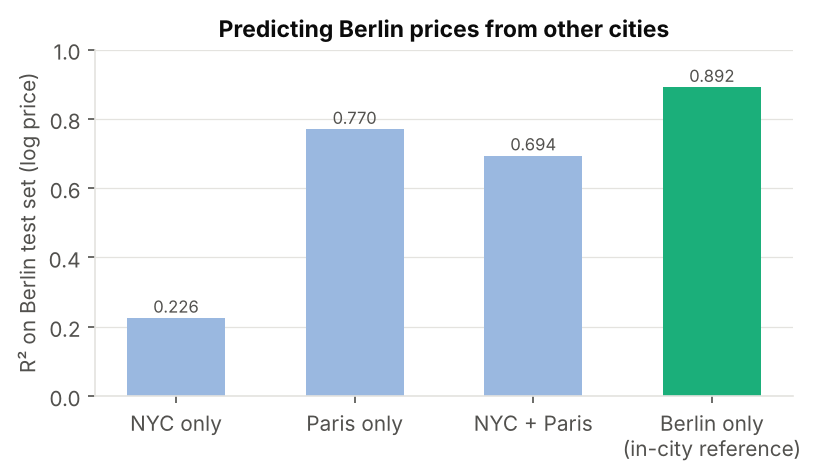

In [14]:
display(Image(str(C.FIG_DIR / "transfer_berlin.png")))

## 5. Using the final model
The final XGBoost model is trained on all three cities with a city indicator and saved to `models/xgb_all_cities.joblib`.

In [15]:
from airbnb.inference import load_bundle, make_listing, predict_price
b = load_bundle()
for city in C.CITIES:
    for room in ["Entire home/apt", "Private room"]:
        x = make_listing(b["defaults"], city, room_type=room, accommodates=2, bedrooms=1)
        print(f"{C.CITIES[city]['name']:14s} {room:16s} ${predict_price(b, x)[0]:.0f}")

New York City  Entire home/apt  $163
New York City  Private room     $114
Paris          Entire home/apt  $237
Paris          Private room     $219
Berlin         Entire home/apt  $184
Berlin         Private room     $156


## 6. Conclusions
See the README and the report in `report/` for the discussion.